In [2]:
#task 1: Data Loading and Understanding

import pandas as pd
#loading data
file_path = 'WA_Fn-UseC_-Telco-Customer-Churn (1).csv'
df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)
print("\nColumn Names & Data Types:\n", df.dtypes)
print("\nFirst 5 Rows:\n", df.head())
print("\nBasic Summary Statistics:\n", df.describe(include='all'))


Dataset Shape: (7043, 21)

Column Names & Data Types:
 customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

First 5 Rows:
    customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795

In [3]:

duplicate_count = df.duplicated().sum()
print(f"Duplicate records found: {duplicate_count}")

#Check initial missing values
print("Missing values per column:\n", df.isnull().sum())

#Handle incorrect data type and hidden blank values in TotalCharges
df['TotalCharges'] = df['TotalCharges'].replace(' ', '0')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'])

#Drop unnecessary columns
df_clean = df.drop(columns=['customerID'])

#Verify final dataset
print(f"Cleaned dataset shape: {df_clean.shape}")
print(df_clean.dtypes)


Duplicate records found: 0
Missing values per column:
 customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Cleaned dataset shape: (7043, 20)
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling

C:\Users\Admin\AppData\Local\Temp\ipykernel_14508\4102671260.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='Churn', palette='Set2')


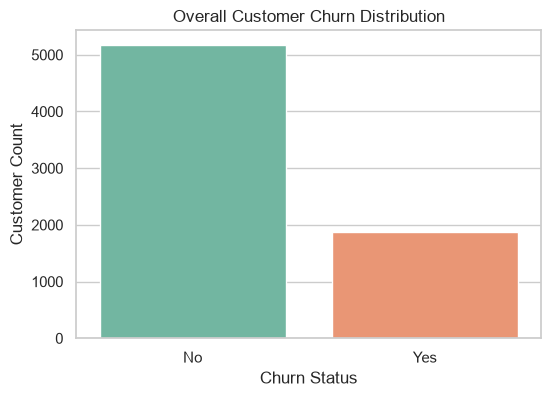

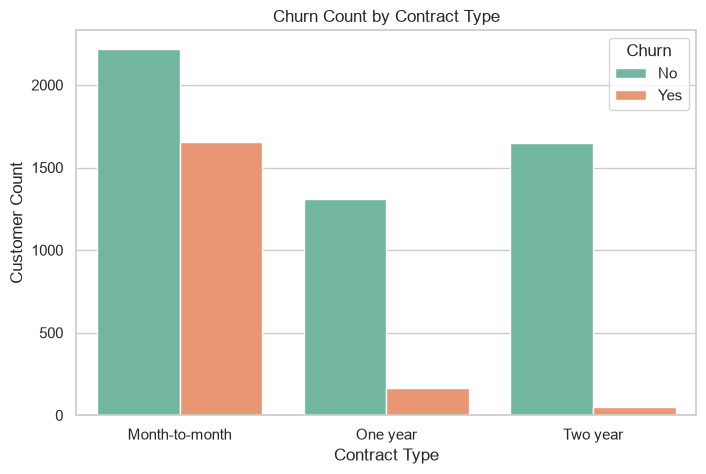

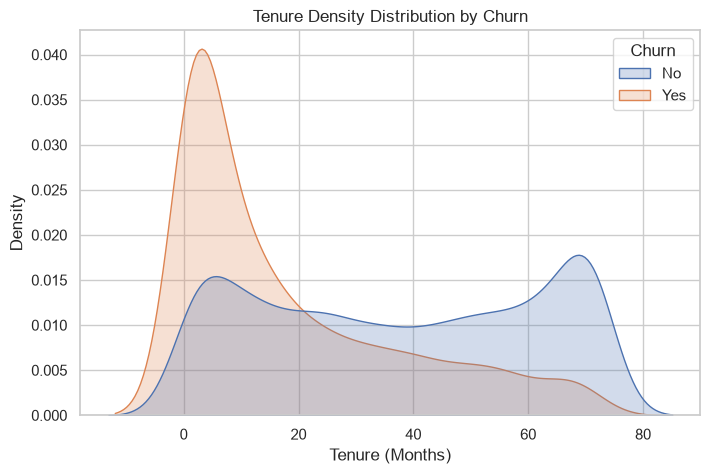

C:\Users\Admin\AppData\Local\Temp\ipykernel_14508\4102671260.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='Churn', y='MonthlyCharges', palette='Set2')


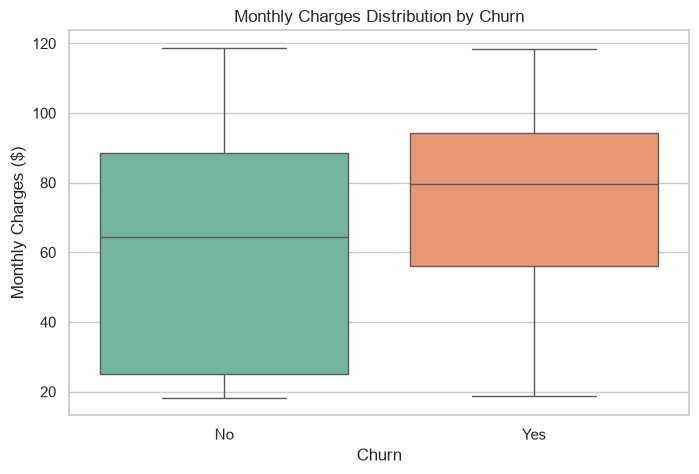

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

# 1. Churn Class Distribution (Target Variable)
plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x='Churn', palette='Set2')
plt.title('Overall Customer Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Customer Count')
plt.show()

# 2. Churn rate by Contract Type
plt.figure(figsize=(8, 5))
sns.countplot(data=df_clean, x='Contract', hue='Churn', palette='Set2')
plt.title('Churn Count by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Customer Count')
plt.show()

# 3. Churn vs Tenure (Customer Loyalty)
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df_clean, x='tenure', hue='Churn', common_norm=False, fill=True)
plt.title('Tenure Density Distribution by Churn')
plt.xlabel('Tenure (Months)')
plt.show()

# 4. Churn vs Monthly Charges
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x='Churn', y='MonthlyCharges', palette='Set2')
plt.title('Monthly Charges Distribution by Churn')
plt.ylabel('Monthly Charges ($)')
plt.show()




In [7]:
from sklearn.model_selection import train_test_split

df_clean['AvgCostPerMonth'] = df_clean['TotalCharges'] / (df_clean['tenure'] + 1)

X = df_clean.drop(columns=['Churn'])
y = df_clean['Churn'].map({'No': 0, 'Yes': 1})

binary_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
multi_cols = ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
              'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
              'Contract', 'PaymentMethod']

for col in binary_cols:
    X[col] = X[col].map({'No': 0, 'Yes': 1, 'Female': 0, 'Male': 1})

X = pd.get_dummies(X, columns=multi_cols, drop_first=True)

print("Input Features Shape (X):", X.shape)
print("Target Vector Shape (y):", y.shape)


Input Features Shape (X): (7043, 31)
Target Vector Shape (y): (7043,)


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

#Split dataset (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

#Scale features (fixes convergence warning)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#Model 1: Logistic Regression
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_scaled, y_train)

#Model 2: Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

print("Training complete with no warnings..............")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)


Training complete with no warnings..............
X_train shape: (5634, 31)
X_test shape: (1409, 31)


In [9]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# 1. Predictions
log_preds = log_model.predict(X_test_scaled)
rf_preds = rf_model.predict(X_test)

# 2. Evaluation Metrics Function
def get_metrics(y_true, y_preds):
    return {
        'Accuracy': round(accuracy_score(y_true, y_preds), 4),
        'Precision': round(precision_score(y_true, y_preds), 4),
        'Recall': round(recall_score(y_true, y_preds), 4),
        'F1-Score': round(f1_score(y_true, y_preds), 4)
    }

log_metrics = get_metrics(y_test, log_preds)
rf_metrics = get_metrics(y_test, rf_preds)

# Display Results
results_df = pd.DataFrame([log_metrics, rf_metrics], index=['Logistic Regression', 'Random Forest'])
print("--- MODEL COMPARISON ---")
print(results_df)

print("\n--- LOGISTIC REGRESSION CONFUSION MATRIX ---")
print(confusion_matrix(y_test, log_preds))

print("\n--- RANDOM FOREST CONFUSION MATRIX ---")
print(confusion_matrix(y_test, rf_preds))


--- MODEL COMPARISON ---
                     Accuracy  Precision  Recall  F1-Score
Logistic Regression    0.8084     0.6757  0.5348    0.5970
Random Forest          0.7878     0.6271  0.4947    0.5531

--- LOGISTIC REGRESSION CONFUSION MATRIX ---
[[939  96]
 [174 200]]

--- RANDOM FOREST CONFUSION MATRIX ---
[[925 110]
 [189 185]]


In [11]:
# 1. Create sample customer data (raw inputs before encoding)
sample_customers = pd.DataFrame([
    {
        'gender': 'Female',
        'SeniorCitizen': 0,
        'Partner': 'Yes',
        'Dependents': 'No',
        'tenure': 1,
        'PhoneService': 'Yes',
        'MultipleLines': 'No',
        'InternetService': 'Fiber optic',
        'OnlineSecurity': 'No',
        'OnlineBackup': 'No',
        'DeviceProtection': 'No',
        'TechSupport': 'No',
        'StreamingTV': 'No',
        'StreamingMovies': 'No',
        'Contract': 'Month-to-month',
        'PaperlessBilling': 'Yes',
        'PaymentMethod': 'Electronic check',
        'MonthlyCharges': 70.35,
        'TotalCharges': 70.35
    },
    {
        'gender': 'Male',
        'SeniorCitizen': 0,
        'Partner': 'Yes',
        'Dependents': 'Yes',
        'tenure': 48,
        'PhoneService': 'Yes',
        'MultipleLines': 'Yes',
        'InternetService': 'DSL',
        'OnlineSecurity': 'Yes',
        'OnlineBackup': 'Yes',
        'DeviceProtection': 'Yes',
        'TechSupport': 'Yes',
        'StreamingTV': 'No',
        'StreamingMovies': 'No',
        'Contract': 'Two year',
        'PaperlessBilling': 'No',
        'PaymentMethod': 'Credit card (automatic)',
        'MonthlyCharges': 65.20,
        'TotalCharges': 3129.60
    }
])

# 2. Apply feature engineering
sample_customers['AvgCostPerMonth'] = sample_customers['TotalCharges'] / (sample_customers['tenure'] + 1)

# 3. Apply binary mapping
for col in binary_cols:
    sample_customers[col] = sample_customers[col].map({'No': 0, 'Yes': 1, 'Female': 0, 'Male': 1})

# 4. Apply one-hot encoding and align columns with training set (X)
sample_encoded = pd.get_dummies(sample_customers, columns=multi_cols, drop_first=True)
sample_encoded = sample_encoded.reindex(columns=X.columns, fill_value=0)

# 5. Scale features using the fitted scaler
sample_scaled = scaler.transform(sample_encoded)

# 6. Predict using final selected model (Logistic Regression)
raw_predictions = log_model.predict(sample_scaled)
probabilities = log_model.predict_proba(sample_scaled)[:, 1]

# 7. Format output table
results = pd.DataFrame({
    'Customer': ['Customer A (New, High Risk)', 'Customer B (Loyal, Low Risk)'],
    'Predicted Class': raw_predictions,
    'Prediction': ['Churn' if p == 1 else 'No Churn' for p in raw_predictions],
    'Churn Probability': [f"{prob * 100:.2f}%" for prob in probabilities]
})

print(results)


                       Customer  Predicted Class Prediction Churn Probability
0   Customer A (New, High Risk)                1      Churn            81.55%
1  Customer B (Loyal, Low Risk)                0   No Churn             1.15%


In [12]:
import joblib,sklearn, pandas, numpy
joblib.dump(log_model, 'model.pkl')           
joblib.dump(scaler, 'scaler.pkl')             
joblib.dump(X.columns.tolist(), 'columns.pkl')  
print(X.columns.tolist())
print( pandas.__version__, sklearn.__version__,numpy.__version__)

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'AvgCostPerMonth', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']
3.0.6 1.9.1 2.5.3
